In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("Cleaned_dataset_sample.csv")

In [ ]:
df.head(5)

,Airline,Source,Departure,Total_stops,Arrival,Destination,Class,Duration_in_hours,Days_left,Fare
0,Air_India,Chennai,Early_Morning,one,Early_Morning,Delhi,Economy,7.43,18,8797
1,Vistara,Kolkata,Evening,zero,Late_Night,Mumbai,Economy,13.41,2,11973
2,SpiceJet,Hyderabad,Morning,zero,Afternoon,Mumbai,Business,11.71,12,23224
3,Vistara,Chennai,Morning,one,Evening,Delhi,Economy,10.69,42,9197
4,SpiceJet,Kolkata,Late_Night,one,Early_Morning,Hyderabad,Economy,11.56,37,6739


In [ ]:
df.shape

(30000, 10)

In [ ]:
df.head(5)

,Airline,Source,Departure,Total_stops,Arrival,Destination,Class,Duration_in_hours,Days_left,Fare
0,Air_India,Chennai,Early_Morning,one,Early_Morning,Delhi,Economy,7.43,18,8797
1,Vistara,Kolkata,Evening,zero,Late_Night,Mumbai,Economy,13.41,2,11973
2,SpiceJet,Hyderabad,Morning,zero,Afternoon,Mumbai,Business,11.71,12,23224
3,Vistara,Chennai,Morning,one,Evening,Delhi,Economy,10.69,42,9197
4,SpiceJet,Kolkata,Late_Night,one,Early_Morning,Hyderabad,Economy,11.56,37,6739


In [ ]:
df.columns

Index(['Date_of_journey', 'Journey_day', 'Airline', 'Flight_code', 'Class',
       'Source', 'Departure', 'Total_stops', 'Arrival', 'Destination',
       'Duration_in_hours', 'Days_left', 'Fare'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48995 entries, 0 to 48994
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date_of_journey    48995 non-null  object 
 1   Journey_day        48995 non-null  object 
 2   Airline            48995 non-null  object 
 3   Flight_code        48995 non-null  object 
 4   Class              48995 non-null  object 
 5   Source             48995 non-null  object 
 6   Departure          48995 non-null  object 
 7   Total_stops        48994 non-null  object 
 8   Arrival            48994 non-null  object 
 9   Destination        48994 non-null  object 
 10  Duration_in_hours  48994 non-null  float64
 11  Days_left          48994 non-null  float64
 12  Fare               48994 non-null  float64
dtypes: float64(3), object(10)
memory usage: 4.9+ MB


In [ ]:
df.isnull().sum()

,0
Date_of_journey,0
Journey_day,0
Airline,0
Flight_code,0
Class,0
Source,0
Departure,0
Total_stops,1
Arrival,1
Destination,1


In [ ]:
df.duplicated().sum()

np.int64(297)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.describe()

,Duration_in_hours,Days_left,Fare
count,48697.000000,48697.000000,48697.000000
mean,10.674225,25.037025,19652.084399
std,7.057129,14.073450,17702.932028
min,1.916700,1.000000,3818.000000
25%,5.333300,13.000000,7726.000000
50%,9.166700,25.000000,10828.000000
75%,14.666700,37.000000,29805.000000
max,41.583300,50.000000,110441.000000


In [ ]:
df["Fare"].describe()

,Fare
count,48697.000000
mean,19652.084399
std,17702.932028
min,3818.000000
25%,7726.000000
50%,10828.000000
75%,29805.000000
max,110441.000000


In [ ]:
base_fare = df["Fare"].mean()

print("Base Fare:", base_fare)

Base Fare: 19652.084399449657


In [ ]:
df = df.copy()

df["Price_Index"] = (df["Fare"] / base_fare) * 100

In [ ]:
df[["Fare", "Price_Index"]].head(10)

,Fare,Price_Index
0,5335.0,27.147248
1,5899.0,30.017172
2,5801.0,29.518497
3,5794.0,29.482878
4,5955.0,30.302129
5,5955.0,30.302129
6,5955.0,30.302129
7,5899.0,30.017172
8,5829.0,29.660976
9,5899.0,30.017172


In [ ]:
overall_index = df["Price_Index"].mean()

print("Overall Airfare Price Index:", round(overall_index, 2))

Overall Airfare Price Index: 100.0


In [ ]:
route_index = df.groupby(
    ["Source", "Destination"]
)["Price_Index"].mean().reset_index()

In [ ]:
route_index = route_index.sort_values(
    "Price_Index",
    ascending=False
)

route_index.head(10)

,Source,Destination,Price_Index
0,Delhi,Bangalore,101.182685
2,Delhi,Mumbai,100.455249
1,Delhi,Hyderabad,97.564788


In [ ]:
route_index.sort_values(
    "Price_Index",
    ascending=True
).head(10)

,Source,Destination,Price_Index
1,Delhi,Hyderabad,97.564788
2,Delhi,Mumbai,100.455249
0,Delhi,Bangalore,101.182685


In [ ]:
airline_index = df.groupby(
    "Airline"
)["Price_Index"].mean().reset_index()

In [ ]:
airline_index = airline_index.sort_values(
    "Price_Index",
    ascending=False
)

In [ ]:
airline_index

,Airline,Price_Index
0,Air India,122.221958
6,Vistara,120.383987
3,GO FIRST,42.534509
1,AirAsia,40.944546
4,Indigo,40.473232
5,SpiceJet,40.303197
2,AkasaAir,30.783249


In [ ]:
days_index = df.groupby(
    "Days_left"
)["Price_Index"].mean().reset_index()

In [ ]:
days_index = days_index.sort_values(
    "Days_left"
)

In [ ]:
days_index.head(20)

,Days_left,Price_Index
0,1.0,142.474790
1,2.0,123.281614
2,3.0,115.675881
3,4.0,118.844866
4,5.0,125.547126
5,6.0,112.140031
6,7.0,124.395285
7,8.0,110.752140
8,9.0,111.240719
9,10.0,112.022351


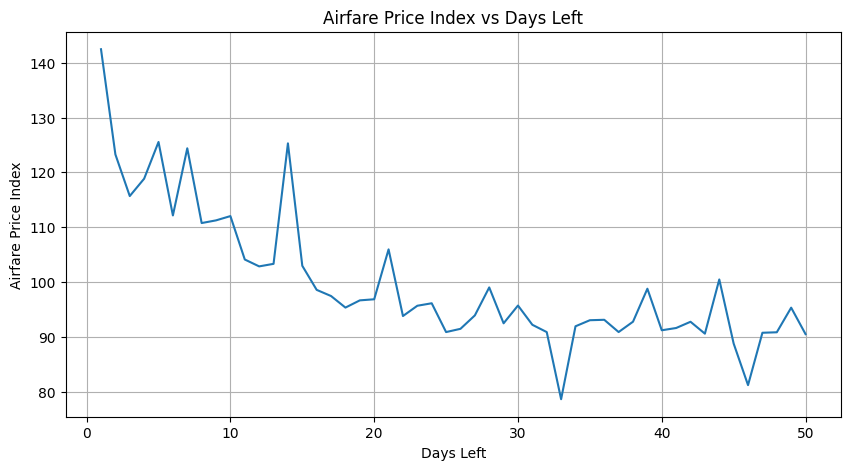

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    days_index["Days_left"],
    days_index["Price_Index"]
)

plt.xlabel("Days Left")
plt.ylabel("Airfare Price Index")
plt.title("Airfare Price Index vs Days Left")

plt.grid()
plt.show()

In [ ]:
airline_index = df.groupby("Airline")["Price_Index"].mean().reset_index()

In [ ]:
airline_index.sort_values("Price_Index", ascending=False)

,Airline,Price_Index
0,Air India,122.221958
6,Vistara,120.383987
3,GO FIRST,42.534509
1,AirAsia,40.944546
4,Indigo,40.473232
5,SpiceJet,40.303197
2,AkasaAir,30.783249


In [ ]:
airline_index = airline_index.sort_values(
    "Price_Index",
    ascending=False
)

In [ ]:
airline_index

,Airline,Price_Index
0,Air India,122.221958
6,Vistara,120.383987
3,GO FIRST,42.534509
1,AirAsia,40.944546
4,Indigo,40.473232
5,SpiceJet,40.303197
2,AkasaAir,30.783249


In [ ]:
df.columns

Index(['Date_of_journey', 'Journey_day', 'Airline', 'Flight_code', 'Class',
       'Source', 'Departure', 'Total_stops', 'Arrival', 'Destination',
       'Duration_in_hours', 'Days_left', 'Fare', 'Price_Index'],
      dtype='object')

In [ ]:
days_index = df.groupby("Days_left")["Price_Index"].mean().reset_index()

In [ ]:
days_index.head(10)

,Days_left,Price_Index
0,1.0,142.474790
1,2.0,123.281614
2,3.0,115.675881
3,4.0,118.844866
4,5.0,125.547126
5,6.0,112.140031
6,7.0,124.395285
7,8.0,110.752140
8,9.0,111.240719
9,10.0,112.022351


In [ ]:
days_index = days_index.sort_values("Days_left")

In [ ]:
days_index

,Days_left,Price_Index
0,1.0,142.474790
1,2.0,123.281614
2,3.0,115.675881
3,4.0,118.844866
4,5.0,125.547126
5,6.0,112.140031
6,7.0,124.395285
7,8.0,110.752140
8,9.0,111.240719
9,10.0,112.022351


In [ ]:
import matplotlib.pyplot as plt

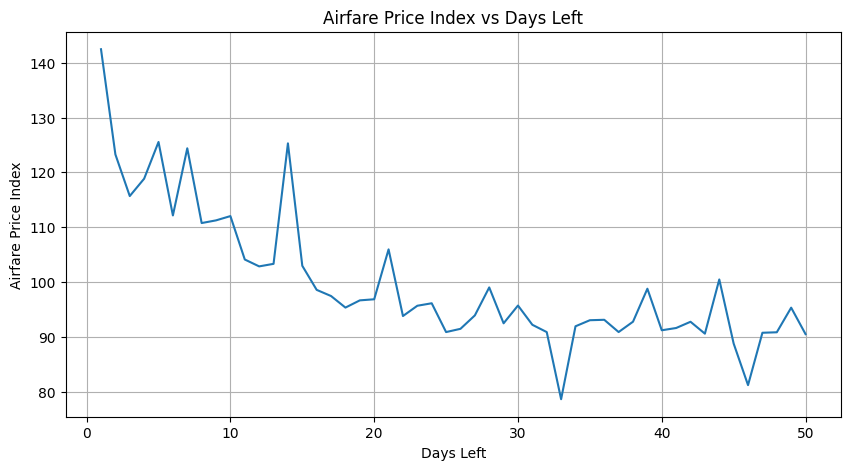

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(days_index["Days_left"], days_index["Price_Index"])
plt.xlabel("Days Left")
plt.ylabel("Airfare Price Index")
plt.title("Airfare Price Index vs Days Left")
plt.grid()
plt.show()

In [ ]:
def recommendation(index):

    if index < 90:
        return "🟢 Good time to book"

    elif index <= 110:
        return "🟡 Average price"

    else:
        return "🔴 High price"

In [ ]:
df["Recommendation"] = df["Price_Index"].apply(
    recommendation
)

In [ ]:
df[
    ["Fare", "Price_Index", "Recommendation"]
].head(20)

,Fare,Price_Index,Recommendation
0,5335.0,27.147248,🟢 Good time to book
1,5899.0,30.017172,🟢 Good time to book
2,5801.0,29.518497,🟢 Good time to book
3,5794.0,29.482878,🟢 Good time to book
4,5955.0,30.302129,🟢 Good time to book
5,5955.0,30.302129,🟢 Good time to book
6,5955.0,30.302129,🟢 Good time to book
7,5899.0,30.017172,🟢 Good time to book
8,5829.0,29.660976,🟢 Good time to book
9,5899.0,30.017172,🟢 Good time to book


In [ ]:
df["Recommendation"].value_counts()

,count
Recommendation,
🟢 Good time to book,33167
🔴 High price,14287
🟡 Average price,1244


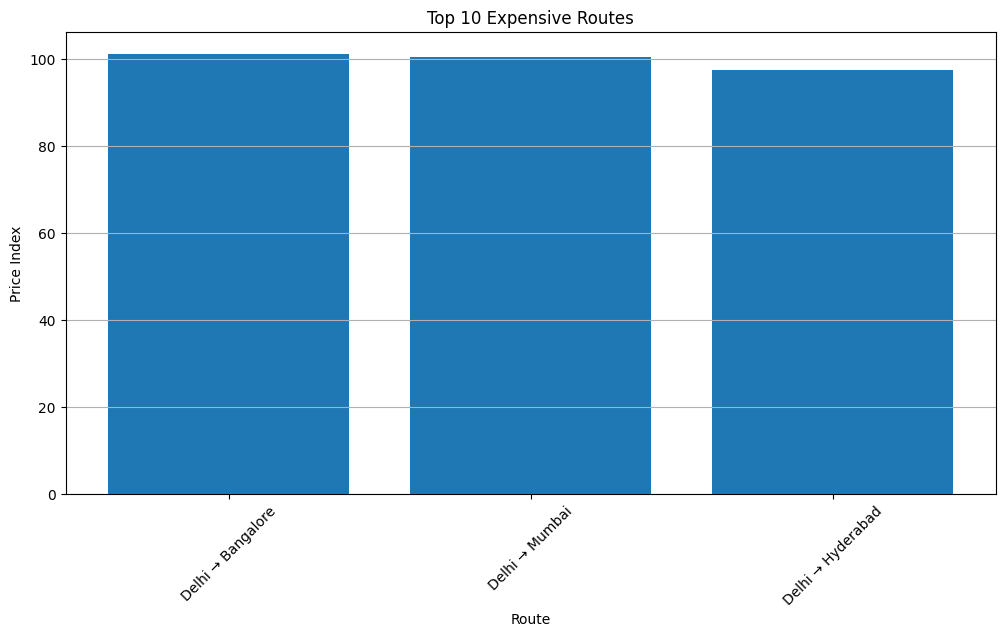

In [ ]:
top_routes = route_index.head(10)

plt.figure(figsize=(12, 6))

route_names = (
    top_routes["Source"]
    + " → "
    + top_routes["Destination"]
)

plt.bar(
    route_names,
    top_routes["Price_Index"]
)

plt.xlabel("Route")
plt.ylabel("Price Index")
plt.title("Top 10 Expensive Routes")

plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

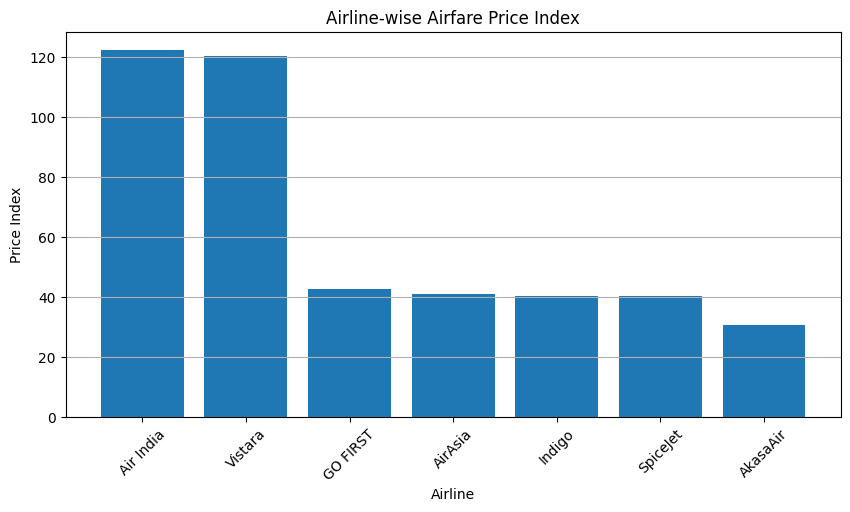

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    airline_index["Airline"],
    airline_index["Price_Index"]
)

plt.xlabel("Airline")
plt.ylabel("Price Index")
plt.title("Airline-wise Airfare Price Index")

plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

In [ ]:
df.to_csv(
    "airfare_index_data.csv",
    index=False
)